## Information Theory Fundamentals

### Learning Goals
* Understand what information theory measures regarding uncertainty and surprise.
* Calculate self-information for events of varying probabilities using base-2 logarithms.
* Define and compute Shannon entropy as the average uncertainty of a discrete random variable.

---

### 1. What is Information?

Information theory measures uncertainty and quantifies how much an observation tells us about an unknown outcome. 

For an event with probability $p(x)$, its **self-information** (or surprise) is defined as:
$$
I(x) = -\log_2 p(x)
$$
Rare events carry more information (higher surprise) when they occur than common events.

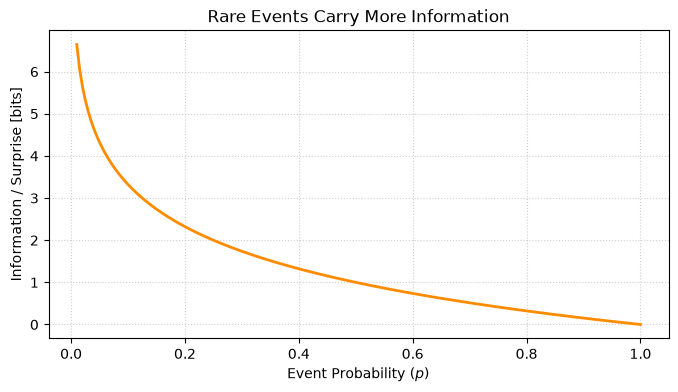

Sample Information Content Values:
  p = 0.5  -> 1.00 bits
  p = 0.1  -> 3.32 bits
  p = 0.01 -> 6.64 bits


In [1]:
import numpy as np
import matplotlib.pyplot as plt

probabilities = np.linspace(0.01, 1.0, 200)
information = -np.log2(probabilities)

plt.figure(figsize=(8, 4))
plt.plot(probabilities, information, color='darkorange', linewidth=2)
plt.xlabel("Event Probability ($p$)")
plt.ylabel("Information / Surprise [bits]")
plt.title("Rare Events Carry More Information")
plt.grid(linestyle=':', alpha=0.6)
plt.show()

print("Sample Information Content Values:")
for p in [0.5, 0.1, 0.01]:
    print(f"  p = {p:<4} -> {-np.log2(p):.2f} bits")

### 2. Shannon Entropy

**Entropy** represents the average uncertainty of a discrete random variable across all possible outcomes:
$$
H(X) = -\sum_x p(x) \log_2 p(x)
$$
Entropy is measured in bits when the logarithm is base 2.

In [2]:
def entropy(probabilities):
    p = np.asarray(probabilities, dtype=float)
    p = p[p > 0]  # Filter out zero probabilities to avoid log2(0)
    return -np.sum(p * np.log2(p))

print(f"Certain outcome [1.0, 0.0]:  entropy = {entropy([1.0, 0.0]):.4f} bits")
print(f"Fair coin [0.5, 0.5]:        entropy = {entropy([0.5, 0.5]):.4f} bits")
print(f"Biased coin [0.9, 0.1]:      entropy = {entropy([0.9, 0.1]):.4f} bits")

Certain outcome [1.0, 0.0]:  entropy = -0.0000 bits
Fair coin [0.5, 0.5]:        entropy = 1.0000 bits
Biased coin [0.9, 0.1]:      entropy = 0.4690 bits


---

### Exercises

Try each problem before running the verification code below:

1. Why does a rare event have more self-information than a common event?
2. Calculate the Shannon entropy for a fair six-sided die.
3. Compare a fair coin with a coin that lands heads $99\%$ of the time. Which has higher entropy?

In [3]:
# --- Exercise Verification & Explanations ---
print("=== Exercise Solutions & Checks ===")

print("\n1. Why Rare Events Carry More Information:")
print("   - Because -log2(p) increases as p approaches zero; learning that an unexpected")
print("     event occurred resolves significantly more uncertainty.")

# 2. Fair six-sided die entropy
die_probs = [1/6] * 6
print(f"\n2. Fair Six-Sided Die Entropy:")
print(f"   - Calculated entropy: {entropy(die_probs):.4f} bits (log2(6) = {np.log2(6):.4f})")

print("\n3. Fair Coin vs. 99% Biased Coin Entropy:")
print("   - The fair coin has higher entropy (1.0 bit) because its outcomes are maximally uncertain,")
print("     whereas the 99% biased coin has very low entropy (~0.08 bits) due to high predictability.")

=== Exercise Solutions & Checks ===

1. Why Rare Events Carry More Information:
   - Because -log2(p) increases as p approaches zero; learning that an unexpected
     event occurred resolves significantly more uncertainty.

2. Fair Six-Sided Die Entropy:
   - Calculated entropy: 2.5850 bits (log2(6) = 2.5850)

3. Fair Coin vs. 99% Biased Coin Entropy:
   - The fair coin has higher entropy (1.0 bit) because its outcomes are maximally uncertain,
     whereas the 99% biased coin has very low entropy (~0.08 bits) due to high predictability.
